In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.feature_selection import SelectKBest, f_classif

# Load dataset
combined_df = pd.read_csv("/Users/lew/Desktop/BUSA8031 Business Analytics Project/group/combined_dataset.csv")
combined_df.head()

/var/folders/_8/8by4rwhj0w5cnmrs6zyb65hr0000gn/T/ipykernel_32271/1274441393.py:13: DtypeWarning: Columns (29,49,50,51) have mixed types. Specify dtype option on import or set low_memory=False.
  combined_df = pd.read_csv("/Users/lew/Desktop/BUSA8031 Business Analytics Project/group/combined_dataset.csv")


,UNIQUE_MQBS_STUDENT_IDENTIFIER,ACADEMIC_YEAR,UNIT_CODE,UNIT_FULL_TITLE,UNIT_OWNING_DEPARTMENT,UNIT_OWNING_FACULTY,UNIT_ATTENDANCE_MODE,UNIT_CORE_OR_FLEXI,UNIT_STATUS,GRADE,...,COURSE_COMPLETION_COUNT_NEW_NORMAL,FACULTY_CONTINUE_ENROLMENT_X1,FACULTY_COMPLETION_COUNT_NEW_NORMAL,MACQUARIE_CONTINUE_ENROLMENT_X1,MACQUARIE_COMPLETION_COUNT_NEW_NORMAL,TRANSFER_COURSE_CODE,TRANSFER_COURSE_FULL_TITLE,TRANSFER_COURSE_OWNING_FACULTY,RET_CODE_TAG,RET_HUB_KEY
0,2500001,2020,AFIN3029,Derivative Instruments,Dept of Applied Finance,Macquarie Business School,INT,Core,Passed,CR,...,1,0,1,0,1,NaN,NaN,NaN,Completed,82420170672b11a573d345c5f575199f\r
1,2500004,2020,ACCG3001,Organisational Planning and Control,Department of Accounting and Corporate Governance,Macquarie Business School,INT,Core,Passed,CR,...,1,0,1,0,1,NaN,NaN,NaN,Completed,47baa365b3889dcf88685716b786135e\r
2,2500005,2020,PICT2010,Intelligence and Counter Intelligence,Department of Security Studies and Criminology,Faculty of Arts,EXT,Flexi,Passed,CR,...,1,0,1,0,1,NaN,NaN,NaN,Completed,a9aaf525680e7e7e1b93709edd22f43f\r
3,2500005,2020,COMP3850,Computing Industry Project,School of Computing,Faculty of Science and Engineering,INT,Core,Passed,D,...,1,0,1,0,1,NaN,NaN,NaN,Completed,a9aaf525680e7e7e1b93709edd22f43f\r
4,2500005,2020,ACCG3025,Cyber Security and Privacy,Department of Accounting and Corporate Governance,Macquarie Business School,INT,Flexi,Passed,CR,...,1,0,1,0,1,NaN,NaN,NaN,Completed,a9aaf525680e7e7e1b93709edd22f43f\r


In [2]:
combined_df["RET_CODE_TAG"].unique()

array(['Completed', 'Not Retained in Year X + 1', 'Course Retained',
       'Faculty Retained', 'MQ Retained'], dtype=object)

In [3]:
combined_df.shape

(284656, 54)

In [4]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284656 entries, 0 to 284655
Data columns (total 54 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   UNIQUE_MQBS_STUDENT_IDENTIFIER         284656 non-null  int64  
 1   ACADEMIC_YEAR                          284656 non-null  int64  
 2   UNIT_CODE                              284656 non-null  object 
 3   UNIT_FULL_TITLE                        284656 non-null  object 
 4   UNIT_OWNING_DEPARTMENT                 284656 non-null  object 
 5   UNIT_OWNING_FACULTY                    284656 non-null  object 
 6   UNIT_ATTENDANCE_MODE                   284656 non-null  object 
 7   UNIT_CORE_OR_FLEXI                     284656 non-null  object 
 8   UNIT_STATUS                            284656 non-null  object 
 9   GRADE                                  278231 non-null  object 
 10  REPEAT_FAIL                            284656 non-null  

### 1. Handling Missing Values

In [5]:
# Count missing values

missing = combined_df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

TRANSFER_COURSE_CODE              270126
TRANSFER_COURSE_FULL_TITLE        270126
TRANSFER_COURSE_OWNING_FACULTY    270126
COURSE_COMPLETION_DATE            132175
GRADE                               6425
dtype: int64

In [6]:
# Impute Missing Values

# Handling Missing Values in GRADE
mask_withdrawn_na = (combined_df['UNIT_STATUS'] == 'Withdrawn') & combined_df['GRADE'].isna()
combined_df.loc[mask_withdrawn_na, 'GRADE'] = 'WD'

In [7]:
# Handling Missing Values in TRANSFER-Related Fields

transfer_cols = ['TRANSFER_COURSE_CODE', 'TRANSFER_COURSE_FULL_TITLE', 'TRANSFER_COURSE_OWNING_FACULTY']
for col in transfer_cols:
    combined_df[col] = combined_df[col].fillna('No Transfer')

In [8]:
# Instead of filling in COURSE_COMPLETION_DATE, create a new feature.
combined_df['COURSE_COMPLETED'] = combined_df['COURSE_COMPLETION_DATE'].notna().astype(int)

In [9]:
combined_df.head()

,UNIQUE_MQBS_STUDENT_IDENTIFIER,ACADEMIC_YEAR,UNIT_CODE,UNIT_FULL_TITLE,UNIT_OWNING_DEPARTMENT,UNIT_OWNING_FACULTY,UNIT_ATTENDANCE_MODE,UNIT_CORE_OR_FLEXI,UNIT_STATUS,GRADE,...,FACULTY_CONTINUE_ENROLMENT_X1,FACULTY_COMPLETION_COUNT_NEW_NORMAL,MACQUARIE_CONTINUE_ENROLMENT_X1,MACQUARIE_COMPLETION_COUNT_NEW_NORMAL,TRANSFER_COURSE_CODE,TRANSFER_COURSE_FULL_TITLE,TRANSFER_COURSE_OWNING_FACULTY,RET_CODE_TAG,RET_HUB_KEY,COURSE_COMPLETED
0,2500001,2020,AFIN3029,Derivative Instruments,Dept of Applied Finance,Macquarie Business School,INT,Core,Passed,CR,...,0,1,0,1,No Transfer,No Transfer,No Transfer,Completed,82420170672b11a573d345c5f575199f\r,1
1,2500004,2020,ACCG3001,Organisational Planning and Control,Department of Accounting and Corporate Governance,Macquarie Business School,INT,Core,Passed,CR,...,0,1,0,1,No Transfer,No Transfer,No Transfer,Completed,47baa365b3889dcf88685716b786135e\r,1
2,2500005,2020,PICT2010,Intelligence and Counter Intelligence,Department of Security Studies and Criminology,Faculty of Arts,EXT,Flexi,Passed,CR,...,0,1,0,1,No Transfer,No Transfer,No Transfer,Completed,a9aaf525680e7e7e1b93709edd22f43f\r,1
3,2500005,2020,COMP3850,Computing Industry Project,School of Computing,Faculty of Science and Engineering,INT,Core,Passed,D,...,0,1,0,1,No Transfer,No Transfer,No Transfer,Completed,a9aaf525680e7e7e1b93709edd22f43f\r,1
4,2500005,2020,ACCG3025,Cyber Security and Privacy,Department of Accounting and Corporate Governance,Macquarie Business School,INT,Flexi,Passed,CR,...,0,1,0,1,No Transfer,No Transfer,No Transfer,Completed,a9aaf525680e7e7e1b93709edd22f43f\r,1


### 2. Feature Engineering

In [10]:
# 2.1 Create 'PROGRESS_PERCENTAGE' feature to quantify each student's advancement within the course

combined_df['PROGRESS_PERCENTAGE'] = (combined_df['COMPLETED_CREDIT_POINTS'] / 
                                     combined_df['COURSE_TOTAL_CREDIT_POINTS'] * 100)

In [11]:
# 2.2 Create 'PERFORMANCE_CATEGORY' feature
# Categorize original grade levels (HD, D, CR, etc.) into broader performance categories
# to facilitate comparison among students at different performance levels.

def get_performance_category(grade):
    if grade in ['HD', 'D']: 
        return 'High'  # HD (85-100), D (75-84)
    elif grade in ['CR', 'P', 'S']: 
        return 'Medium'  # CR (65-74), P (50-64), S (Pass in Pass/Fail)
    elif grade in ['F', 'FA', 'FH', 'SC']: 
        return 'Fail'  # F, FA (0-49), FH (49), SC (0-49 due to COVID)
    elif grade == 'WD': 
        return 'Withdrawn'
    else: 
        return 'Other'

combined_df['PERFORMANCE_CATEGORY'] = combined_df['GRADE'].apply(get_performance_category)

In [12]:
# 2.3 Create 'STUDY_DURATION_YEARS' feature

combined_df['COURSE_START_DATE'] = pd.to_datetime(combined_df['COURSE_START_DATE'])
combined_df['COURSE_COMPLETION_DATE'] = pd.to_datetime(combined_df['COURSE_COMPLETION_DATE'])

# Only students who have completed the course will have their study duration counted

combined_df['STUDY_DURATION_YEARS'] = np.where(
    combined_df['COURSE_COMPLETED'],
    (combined_df['COURSE_COMPLETION_DATE'] - combined_df['COURSE_START_DATE']).dt.days / 365.25,
    np.nan # Students who have not completed the course are marked as missing values
)

In [13]:
combined_df['COURSE_START_DATE'].head()

0   2007-02-26
1   2004-03-01
2   2009-02-23
3   2009-02-23
4   2009-02-23
Name: COURSE_START_DATE, dtype: datetime64[ns]

In [14]:
combined_df['STUDY_DURATION_YEARS'].head()

0    13.371663
1    16.375086
2    11.791923
3    11.791923
4    11.791923
Name: STUDY_DURATION_YEARS, dtype: float64

In [15]:
# 2.4 Create 'SEMESTER_EFTSL_LOAD' & 'SEMESTER_UNIT_COUNT' features
# Combine the year and semester into a unique identifier to facilitate semester-based analysis of student performance.

combined_df['UNIT_STUDY_PERIOD_START_DATE'] = pd.to_datetime(combined_df['UNIT_STUDY_PERIOD_START_DATE'])
combined_df['YEAR_SEMESTER'] = combined_df['ACADEMIC_YEAR'].astype(str) + '_' + combined_df['UNIT_STUDY_PERIOD']

# Calculate the academic workload for each semester, taking into account the relative difficulty and time requirements of different courses.

semester_load = combined_df.groupby(['UNIQUE_MQBS_STUDENT_IDENTIFIER', 'YEAR_SEMESTER']).agg({
    'UNIT_EFTSL': 'sum', # Using EFTSL as a measure of study load
    'UNIT_CODE': 'count' # Calculate the number of units taken each semester
}).rename(columns={'UNIT_EFTSL': 'SEMESTER_EFTSL_LOAD', 'UNIT_CODE': 'SEMESTER_UNIT_COUNT'})

combined_df = combined_df.merge(semester_load, on=['UNIQUE_MQBS_STUDENT_IDENTIFIER', 'YEAR_SEMESTER'])

In [16]:
# 2.5 Create 'UNIT_LEVEL_CATEGORY' feature
# Classifying course levels into grade categories facilitates analysis of student performance 
# across different stages of academic progression.

def get_unit_level_category(unit_level):
    if '100' in unit_level:
        return 'First_Year'
    elif '200' in unit_level:
        return 'Second_Year'
    elif '300' in unit_level:
        return 'Third_Year'
    elif '400' in unit_level or '500' in unit_level:
        return 'Advanced_Undergraduate'
    elif '700' in unit_level:
        return 'Postgraduate'
    else:
        return 'Other'

combined_df['UNIT_LEVEL_CATEGORY'] = combined_df['UNIT_LEVEL'].apply(get_unit_level_category)

In [17]:
# 2.6 Create student aggregate features
# These attributes will be used for student-level analysis and modeling, 
# such as predicting student risk and analyzing student group characteristics.

student_features = combined_df.groupby('UNIQUE_MQBS_STUDENT_IDENTIFIER').agg({
    'CURRENT_WEIGHTED_AVERAGE_MARK': 'first',  # WAM
    'GENDER': 'first',  # GENDER
    'ACTUAL_AGE': 'first',  # AGE
    'DOMESTIC_OR_INTERNATIONAL': 'first',  # STUDENT_TYPE
    'COURSE_FULL_TITLE': 'first',  # COURSE
    'COURSE_COMPLETED': 'first',  # COURSE_COMPLETED
    'PROGRESS_PERCENTAGE': 'first',  # PROGRESS
    'STUDY_DURATION_YEARS': 'first',  # DURATION
    'ACADEMIC_YEAR_ATTENDANCE_TYPE': 'first', # ATTENDANCE_TYPE
    'ENGLISH_SPEAKING_BACKGROUND': 'first', # ENGLISH_BACKGROUND
    'EQUITY_FLAG': 'first',  # EQUITY_FLAG
    
    # Academic performance
    'UNIT_CODE': 'count',  # TOTAL_UNITS
    'PERFORMANCE_CATEGORY': lambda x: (x == 'Fail').sum(),  # FAIL_COUNT
    'GRADE': lambda x: (x == 'WD').sum(),  # WITHDRAWAL_COUNT
    'REPEAT_FAIL': lambda x: (x == 'Y').sum(),  # REPEAT_FAIL_COUNT
    
    # Learning Load
    'SEMESTER_EFTSL_LOAD': ['mean', 'std'],  # AVG_SEMESTER_EFTSL & STD_SEMESTER_EFTSL
    
    # Course Level Distribution
    'UNIT_LEVEL_CATEGORY': lambda x: (x == 'Third_Year').sum(),  # ADVANCED_UNITS_COUNT
    
    # Retention Rate Metrics
    'COURSE_CONTINUE_ENROLMENT_X1': 'first',  # COURSE_CONTINUE
    'FACULTY_CONTINUE_ENROLMENT_X1': 'first',  # FACULTY_CONTINUE
    'MACQUARIE_CONTINUE_ENROLMENT_X1': 'first',  # MACQUARIE_CONTINUE
    'RET_CODE_TAG': 'first'  # RETENTION_STATUS
}).reset_index()


student_features.columns = [
    'UNIQUE_MQBS_STUDENT_IDENTIFIER', 'WAM', 'GENDER', 'AGE', 'STUDENT_TYPE', 
    'COURSE', 'COURSE_COMPLETED', 'PROGRESS', 'DURATION', 'ATTENDANCE_TYPE',
    'ENGLISH_BACKGROUND', 'EQUITY_FLAG', 'TOTAL_UNITS', 'FAIL_COUNT', 
    'WITHDRAWAL_COUNT', 'REPEAT_FAIL_COUNT', 'AVG_SEMESTER_EFTSL', 
    'STD_SEMESTER_EFTSL', 'ADVANCED_UNITS_COUNT', 'COURSE_CONTINUE',
    'FACULTY_CONTINUE', 'MACQUARIE_CONTINUE', 'RETENTION_STATUS'
]

In [18]:
# 2.7 Create 'AT_RISK' Indicator

def identify_at_risk_students(df):
    conditions = [
        df['FAIL_COUNT'] > 2,  # Failed more than 2 courses - poor academic performance
        df['WITHDRAWAL_COUNT'] > 3,  # Withdrew from more than 3 courses - potential motivation or adaptation issues
        df['REPEAT_FAIL_COUNT'] > 0,  # Repeatedly failed courses - significant learning difficulties
        df['PROGRESS'] < 50,  # Progress below 50% - Lagging academic progress
        df['WAM'] < 50,  # Weighted average below 50 - Overall poor academic performance
        df['RETENTION_STATUS'] == 'Not Retained in Year X+1'  # Not retained - Confirmed withdrawal
    ]
    df['AT_RISK'] = np.any(conditions, axis=0).astype(int)  # Marked as at-risk if any condition is met
    return df

student_features = identify_at_risk_students(student_features)
f"Student features shape: {student_features.shape}"

'Student features shape: (21814, 24)'

In [19]:
risk_counts = student_features['AT_RISK'].value_counts()
risk_counts

f"Percentage of at-risk students: {(risk_counts[1] / len(student_features) * 100):.2f}%"

'Percentage of at-risk students: 47.17%'

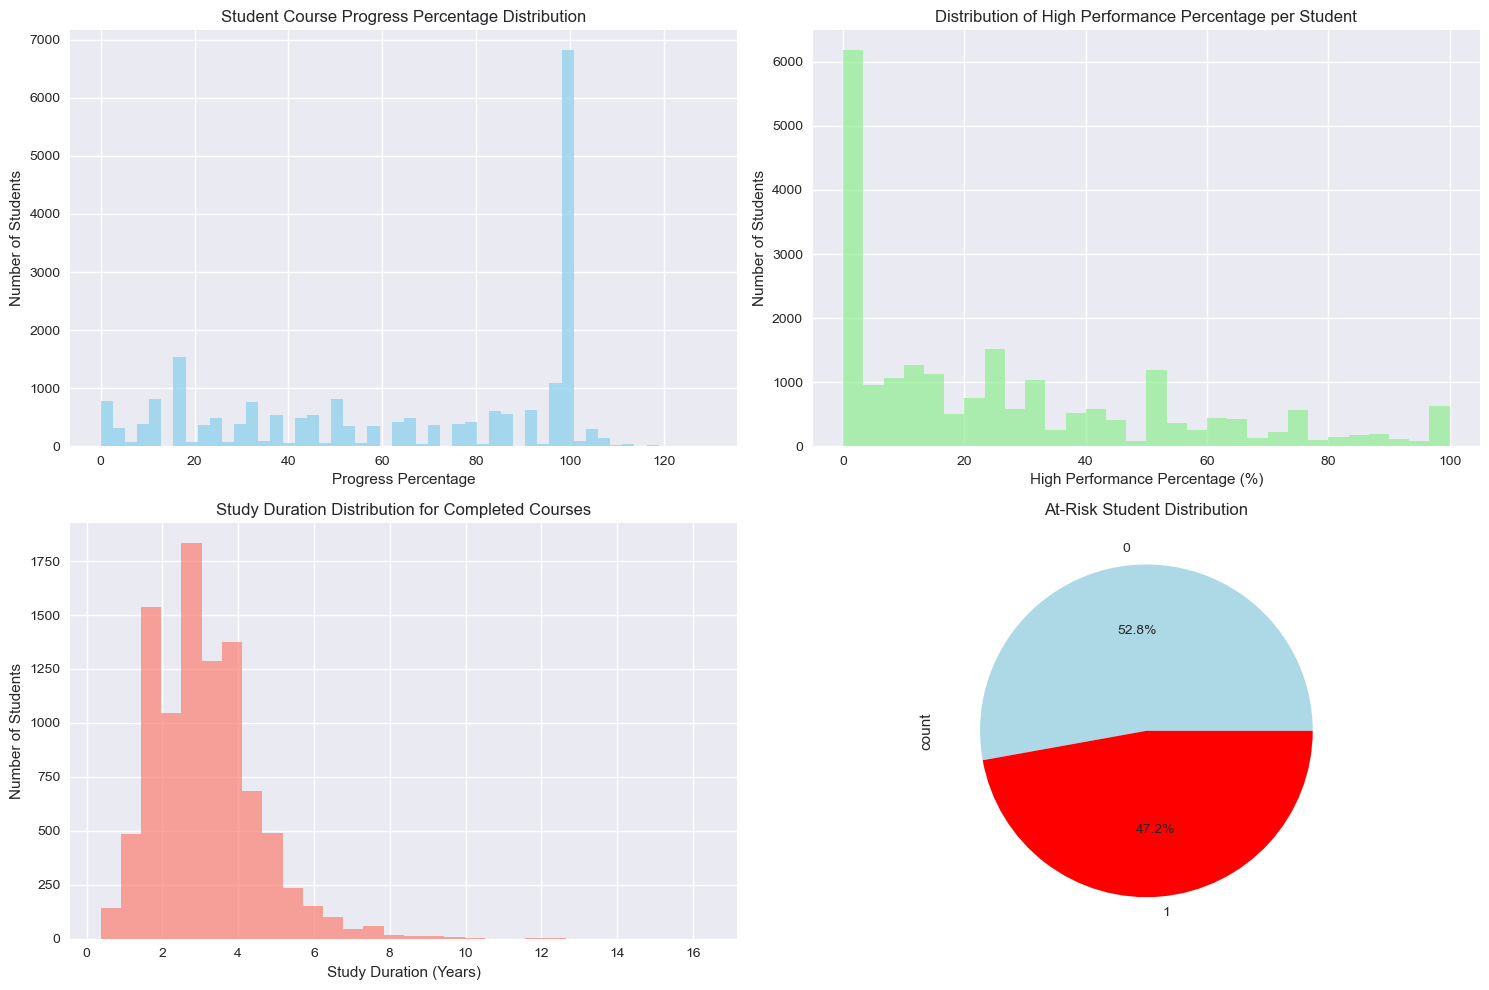

In [21]:
# 2.8 Generate distribution visualizations

plt.style.use('seaborn-v0_8')
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Progress percentage distribution
axes[0,0].hist(student_features['PROGRESS'].dropna(), bins=50, alpha=0.7, color='skyblue')
axes[0,0].set_title('Student Course Progress Percentage Distribution')
axes[0,0].set_xlabel('Progress Percentage')
axes[0,0].set_ylabel('Number of Students')

# 2. Academic performance distribution (student-level average performance)
# Calculate the percentage of high performance courses for each student
performance_avg = combined_df.groupby('UNIQUE_MQBS_STUDENT_IDENTIFIER')['PERFORMANCE_CATEGORY'].apply(
    lambda x: (x == 'High').mean() * 100
)
performance_avg.hist(bins=30, ax=axes[0,1], alpha=0.7, color='lightgreen')
axes[0,1].set_title('Distribution of High Performance Percentage per Student')
axes[0,1].set_xlabel('High Performance Percentage (%)')
axes[0,1].set_ylabel('Number of Students')

# 3. Study duration distribution (only for completed courses)
completed_duration = student_features[student_features['COURSE_COMPLETED'] == True]['DURATION']
completed_duration.hist(bins=30, ax=axes[1,0], alpha=0.7, color='salmon')
axes[1,0].set_title('Study Duration Distribution for Completed Courses')
axes[1,0].set_xlabel('Study Duration (Years)')
axes[1,0].set_ylabel('Number of Students')

# 4. At-risk student distribution
risk_counts.plot(kind='pie', autopct='%1.1f%%', ax=axes[1,1], colors=['lightblue', 'red'])
axes[1,1].set_title('At-Risk Student Distribution')

plt.tight_layout()
plt.show()

### 3. CORRELATION VALIDATION

#### 3.1 What are the factors taken by students who complete on-time vs. those who take longer?

In [22]:
combined_df["COURSE_TYPE"] = np.where(
    combined_df["COURSE_FULL_TITLE"].str.contains(" and ", case=False, na=False),
    "Double Degree",
    "Single Degree"
)

In [23]:
median_single = combined_df.loc[combined_df["COURSE_TYPE"] == "Single Degree", "STUDY_DURATION_YEARS"].median()
median_double = combined_df.loc[combined_df["COURSE_TYPE"] == "Double Degree", "STUDY_DURATION_YEARS"].median()

print("Median duration (single degree):", round(median_single, 2))
print("Median duration (double degree):", round(median_double, 2))

Median duration (single degree): 2.79
Median duration (double degree): 3.78


In [24]:
combined_df["COMPLETION_GROUP"] = np.where(
    ((combined_df["COURSE_TYPE"] == "Single Degree") & 
     (combined_df["STUDY_DURATION_YEARS"] <= median_single)) |
    ((combined_df["COURSE_TYPE"] == "Double Degree") & 
     (combined_df["STUDY_DURATION_YEARS"] <= median_double)),
    "OnTime",
    "Longer"
)

In [25]:
agg_df = combined_df.groupby(
    ["UNIQUE_MQBS_STUDENT_IDENTIFIER", "COMPLETION_GROUP"], as_index=False
).agg({
    "ACTUAL_AGE": "max",
    "SEMESTER_EFTSL_LOAD": "mean",
    "UNIT_ATTENDANCE_MODE": "first",
    "DOMESTIC_OR_INTERNATIONAL": "first",
    "ENGLISH_SPEAKING_BACKGROUND": "first",
    "COURSE_FULL_TITLE": "first",
})

In [26]:
bins = [0, 0.25, 0.75, 1.0]
labels = ["Light", "Medium", "Heavy"]
agg_df["STUDY_LOAD_GROUP"] = pd.cut(
    agg_df["SEMESTER_EFTSL_LOAD"], bins=bins, labels=labels, include_lowest=True
)

In [27]:
combined_df["STUDY_LOAD_GROUP"] = pd.cut(
    combined_df["SEMESTER_EFTSL_LOAD"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [28]:
from scipy.stats import mannwhitneyu

on_time_age = agg_df.loc[agg_df["COMPLETION_GROUP"]=="OnTime", "ACTUAL_AGE"]
longer_age  = agg_df.loc[agg_df["COMPLETION_GROUP"]=="Longer", "ACTUAL_AGE"]

stat, p = mannwhitneyu(on_time_age, longer_age)
print(f"Age difference test: U={stat:.3f}, p={p:.3f}")

Age difference test: U=61417376.500, p=0.000


In [29]:
agg_df.groupby("COMPLETION_GROUP")["ACTUAL_AGE"].describe()

,count,mean,std,min,25%,50%,75%,max
COMPLETION_GROUP,,,,,,,,
Longer,16836.0,21.927536,3.425126,17.0,20.0,21.0,23.0,73.0
OnTime,5790.0,22.611744,2.498409,19.0,21.0,22.0,23.0,69.0


-The p-value < 0.001: the age difference between groups is statistically significant.

-Mean age: On-Time students are slightly older on average (22.6 yrs) than Longer students (21.9 yrs).

-Median age: On-Time median = 22 yrs, Longer = 21 yrs: still a small but consistent gap.

In [30]:
from scipy.stats import chi2_contingency

categorical_factors = [
    "UNIT_ATTENDANCE_MODE",      # unit combination
    "STUDY_LOAD_GROUP",          # light/medium/heavy
    "DOMESTIC_OR_INTERNATIONAL",
    "ENGLISH_SPEAKING_BACKGROUND",
    "COURSE_FULL_TITLE"
]

for col in categorical_factors:
    table = pd.crosstab(agg_df["COMPLETION_GROUP"], agg_df[col])
    chi2, p, dof, expected = chi2_contingency(table)
    print(f"{col}: chi2={chi2:.3f}, p={p:.3f}")

UNIT_ATTENDANCE_MODE: chi2=34.433, p=0.000
STUDY_LOAD_GROUP: chi2=96.714, p=0.000
DOMESTIC_OR_INTERNATIONAL: chi2=1449.076, p=0.000
ENGLISH_SPEAKING_BACKGROUND: chi2=1390.121, p=0.000
COURSE_FULL_TITLE: chi2=1141.019, p=0.000


In [31]:
# 1. Attendance type
pd.crosstab(agg_df["UNIT_ATTENDANCE_MODE"], agg_df["COMPLETION_GROUP"], normalize="index") * 100

COMPLETION_GROUP,Longer,OnTime
UNIT_ATTENDANCE_MODE,,
EXT,69.560000,30.440000
INT,75.012422,24.987578


In [32]:
# 2. Study load group
pd.crosstab(agg_df["STUDY_LOAD_GROUP"], agg_df["COMPLETION_GROUP"], normalize="index") * 100

COMPLETION_GROUP,Longer,OnTime
STUDY_LOAD_GROUP,,
Light,84.439225,15.560775
Medium,73.593653,26.406347


In [33]:
# 3. Domestic / International
pd.crosstab(agg_df["DOMESTIC_OR_INTERNATIONAL"], agg_df["COMPLETION_GROUP"], normalize="index") * 100

COMPLETION_GROUP,Longer,OnTime
DOMESTIC_OR_INTERNATIONAL,,
Domestic,80.911579,19.088421
International,55.635739,44.364261


In [34]:
# 4. English background
pd.crosstab(agg_df["ENGLISH_SPEAKING_BACKGROUND"], agg_df["COMPLETION_GROUP"], normalize="index") * 100

COMPLETION_GROUP,Longer,OnTime
ENGLISH_SPEAKING_BACKGROUND,,
English Speaking Background,79.331574,20.668426
No Information,83.853606,16.146394
Non-English Speaking Background,54.994303,45.005697


In [35]:
# 5. Course
# Create the crosstab for course vs completion group
course_table = pd.crosstab(
    agg_df["COURSE_FULL_TITLE"],
    agg_df["COMPLETION_GROUP"],
    normalize="index"
) * 100

# Sort by 'OnTime' column (highest to lowest)
course_table_sorted = course_table.sort_values(by="OnTime", ascending=False)

# Display top 10 and bottom 10
print("Top 10 courses with highest on-time completion rates:")
display(course_table_sorted.head(10))

Top 10 courses with highest on-time completion rates:


COMPLETION_GROUP,Longer,OnTime
COURSE_FULL_TITLE,,
Bachelor of Mathematical Sciences and Bachelor of Economics,0.000000,100.000000
Bachelor of Business and Bachelor of Applied Finance,0.000000,100.000000
Bachelor of Business Leadership and Commerce,34.020619,65.979381
Bachelor of Professional Practice and Bachelor of Professional Accounting,46.153846,53.846154
Bachelor of Marketing and Media,58.828996,41.171004
Bachelor of Professional Accounting,58.959538,41.040462
Bachelor of Commerce and Bachelor of Professional Accounting,59.090909,40.909091
Bachelor of Applied Finance,65.230167,34.769833
Bachelor of Arts and Bachelor of Professional Accounting,66.666667,33.333333


The analysis showed that several factors strongly influence whether students finish their degrees within the average time of 2.9 years. Younger students, external learners, those with heavier study loads, and international students from non-English-speaking backgrounds were more likely to complete on time. Overall, the findings highlight that both personal characteristics and study patterns play an important role in determining how quickly students complete their studies.

#### 3.2 At what study load (EFTSL) do part-time students show higher attrition risk?

In [36]:
part_time_df = combined_df[
    combined_df["ACADEMIC_YEAR_ATTENDANCE_TYPE"] == "Part Time"
]

In [37]:
# Bring AT_RISK into combined_df (one-to-many: many unit rows per student)
combined_df = combined_df.merge(
    student_features[["UNIQUE_MQBS_STUDENT_IDENTIFIER", "AT_RISK"]],
    on="UNIQUE_MQBS_STUDENT_IDENTIFIER",
    how="left",
    validate="m:1"  # many combined_df rows to 1 student_features row
)

In [38]:
# Collapse to one record per student per semester
semester_level = (
    combined_df.groupby(["UNIQUE_MQBS_STUDENT_IDENTIFIER", "YEAR_SEMESTER"])
    .agg({
        "SEMESTER_EFTSL_LOAD": "first",  # same value repeated anyway
        "AT_RISK": "first"               # same student-level risk flag
    })
    .reset_index()
)

# Bin EFTSL
bins = [0, 0.125, 0.25, 0.375, 0.5, 0.75, 1.0]
labels = ["≤0.125","0.125–0.25","0.25–0.375","0.375–0.5","0.5–0.75","0.75–1.0"]
semester_level["EFTSL_BIN"] = pd.cut(
    semester_level["SEMESTER_EFTSL_LOAD"],
    bins=bins, labels=labels, include_lowest=True
)

# Risk rate by EFTSL bin
risk_by_bin = (
    semester_level.groupby("EFTSL_BIN")["AT_RISK"]
    .mean()
    .rename("Risk_Rate")
    .reset_index()
)

print(risk_by_bin)

    EFTSL_BIN  Risk_Rate
0      ≤0.125   0.446934
1  0.125–0.25   0.501101
2  0.25–0.375   0.467613
3   0.375–0.5   0.405030
4    0.5–0.75   0.232733
5    0.75–1.0        NaN


Students with very light study loads (≤0.25 EFTSL) face the highest risk of dropping out, with attrition rates around 45–50%. As the study load increases, this risk gradually decreases. Once students take more than 0.5 EFTSL, the attrition rate drops sharply to about 23%. There are no part-time students with study loads near full-time (≥0.75 EFTSL), so that category remains empty in the analysis.

In [39]:
from scipy.stats import pointbiserialr, chi2_contingency
import pandas as pd

# Numeric factors in student_features
numeric_vars = ["FAIL_COUNT", "REPEAT_FAIL_COUNT", "WITHDRAWAL_COUNT", "WAM", "PROGRESS"]

for col in numeric_vars:
    r, p = pointbiserialr(student_features["AT_RISK"], student_features[col])
    print(f"{col}: r={r:.3f}, p={p:.3f}")

# Categorical factor
table = pd.crosstab(student_features["STUDENT_TYPE"], student_features["AT_RISK"])
chi2, p, dof, exp = chi2_contingency(table)
print(f"DOMESTIC_OR_INTERNATIONAL: χ²={chi2:.3f}, p={p:.3f}")

FAIL_COUNT: r=0.474, p=0.000
REPEAT_FAIL_COUNT: r=0.303, p=0.000
WITHDRAWAL_COUNT: r=0.216, p=0.000
WAM: r=-0.456, p=0.000
PROGRESS: r=-0.743, p=0.000
DOMESTIC_OR_INTERNATIONAL: χ²=712.306, p=0.000


In [40]:
# Average values for at-risk vs not-at-risk students
performance_summary = (
    student_features.groupby("AT_RISK")[["FAIL_COUNT", "REPEAT_FAIL_COUNT", "WITHDRAWAL_COUNT", "WAM", "PROGRESS"]]
    .mean()
    .round(2)
)
print(performance_summary)

         FAIL_COUNT  REPEAT_FAIL_COUNT  WITHDRAWAL_COUNT    WAM  PROGRESS
AT_RISK                                                                  
0              0.29               0.00              0.08  68.73     89.97
1              2.99               0.66              0.53  53.99     37.11


In [41]:
pd.crosstab(student_features["WITHDRAWAL_COUNT"], student_features["AT_RISK"], normalize="index").round(2)

AT_RISK,0,1
WITHDRAWAL_COUNT,,
0,0.57,0.43
1,0.35,0.65
2,0.24,0.76
3,0.19,0.81
4,0.00,1.00
5,0.00,1.00
6,0.00,1.00
7,0.00,1.00
8,0.00,1.00


In [42]:
# STUDENT_TYPE
pd.crosstab(student_features["STUDENT_TYPE"], student_features["AT_RISK"], normalize="index").round(2)

AT_RISK,0,1
STUDENT_TYPE,,
Domestic,0.48,0.52
International,0.68,0.32


In [43]:
# SEMESTER_EFTSL_LOAD
pd.crosstab(
    combined_df["SEMESTER_EFTSL_LOAD"],
    student_features["AT_RISK"],
    normalize="index"
).round(2)

AT_RISK,0,1
SEMESTER_EFTSL_LOAD,,
0.125,0.57,0.43
0.250,0.55,0.45
0.375,0.51,0.49
0.500,0.53,0.47
0.625,0.56,0.44


-Students who fail more units, withdraw frequently, or repeat subjects tend to face greater challenges and are more likely to drop out. 

-Lower grades (WAM) or slower academic progress are also at higher risk. 

-The strong negative correlation with progress (r = –0.743) indicates that students who complete fewer units or credits than expected in their course plan are the most vulnerable. 

-The Chi-square test (χ² = 712.306, p < 0.001) revealed that domestic students are significantly more likely to be at risk compared to international students, possibly due to factors such as part-time work commitments, time constraints, or lower levels of engagement.

In [45]:
student_features.head()

,UNIQUE_MQBS_STUDENT_IDENTIFIER,WAM,GENDER,AGE,STUDENT_TYPE,COURSE,COURSE_COMPLETED,PROGRESS,DURATION,ATTENDANCE_TYPE,...,WITHDRAWAL_COUNT,REPEAT_FAIL_COUNT,AVG_SEMESTER_EFTSL,STD_SEMESTER_EFTSL,ADVANCED_UNITS_COUNT,COURSE_CONTINUE,FACULTY_CONTINUE,MACQUARIE_CONTINUE,RETENTION_STATUS,AT_RISK
0,2500001,57.20,Male,48,Domestic,Bachelor of Applied Finance,1,104.166667,13.371663,Part Time,...,0,0,0.125,NaN,1,0,0,0,Completed,0
1,2500002,68.08,Female,69,Domestic,Bachelor of Commerce,0,75.000000,NaN,Part Time,...,0,0,0.225,0.052705,5,1,1,1,Course Retained,0
2,2500003,83.80,Female,46,Domestic,Bachelor of Commerce,0,62.500000,NaN,Part Time,...,0,0,0.125,0.000000,2,1,1,1,Course Retained,0
3,2500004,74.68,Female,50,Domestic,Bachelor of Professional Accounting,1,104.166667,16.375086,Part Time,...,0,0,0.125,NaN,1,0,0,0,Completed,0
4,2500005,45.22,Male,35,Domestic,Bachelor of Commerce,1,100.000000,11.791923,Full Time,...,1,0,0.375,0.000000,3,0,0,0,Completed,1


In [46]:
for col in student_features.columns:
    print(col)

UNIQUE_MQBS_STUDENT_IDENTIFIER
WAM
GENDER
AGE
STUDENT_TYPE
COURSE
COURSE_COMPLETED
PROGRESS
DURATION
ATTENDANCE_TYPE
ENGLISH_BACKGROUND
EQUITY_FLAG
TOTAL_UNITS
FAIL_COUNT
WITHDRAWAL_COUNT
REPEAT_FAIL_COUNT
AVG_SEMESTER_EFTSL
STD_SEMESTER_EFTSL
ADVANCED_UNITS_COUNT
COURSE_CONTINUE
FACULTY_CONTINUE
MACQUARIE_CONTINUE
RETENTION_STATUS
AT_RISK


In [47]:
for col in combined_df.columns:
    print(col)

UNIQUE_MQBS_STUDENT_IDENTIFIER
ACADEMIC_YEAR
UNIT_CODE
UNIT_FULL_TITLE
UNIT_OWNING_DEPARTMENT
UNIT_OWNING_FACULTY
UNIT_ATTENDANCE_MODE
UNIT_CORE_OR_FLEXI
UNIT_STATUS
GRADE
REPEAT_FAIL
UNIT_CREDIT_POINT
UNIT_EFTSL
UNIT_FIELD_OF_EDUCATION
UNIT_LEVEL
UNIT_STUDY_PERIOD
UNIT_STUDY_PERIOD_START_DATE
UNIT_STUDY_PERIOD_END_DATE
ACADEMIC_YEAR_ATTENDANCE_MODE
ACADEMIC_YEAR_ATTENDANCE_TYPE
ACADEMIC_YEAR_COMMENCING_CONTINUING
APPLICATION_PATH
LEVEL_OF_STUDY
COMBINED_COURSE
COURSE_CODE
COURSE_FULL_TITLE
COURSE_OWNING_FACULTY
CURRENT_COURSE_STATUS
COURSE_START_DATE
COURSE_COMPLETION_DATE
COURSE_TOTAL_CREDIT_POINTS
CREDITED_CREDIT_POINTS
ADVANCED_STANDING_CREDIT_POINTS
COMPLETED_CREDIT_POINTS
CURRENT_WEIGHTED_AVERAGE_MARK
COURSE_FIELD_OF_EDUCATION
GENDER
ACTUAL_AGE
CITIZENSHIP
DOMESTIC_OR_INTERNATIONAL
ENGLISH_SPEAKING_BACKGROUND
EQUITY_FLAG
HUB_COURSE_ADMISSION_KEY
COURSE_CONTINUE_ENROLMENT_X1
COURSE_COMPLETION_COUNT_NEW_NORMAL
FACULTY_CONTINUE_ENROLMENT_X1
FACULTY_COMPLETION_COUNT_NEW_NORMAL
MACQUA

### 4. FEATURE SCALING

In [48]:
numeric_features = ['WAM', 'AGE', 'PROGRESS', 'DURATION', 'TOTAL_UNITS', 
                   'FAIL_COUNT', 'WITHDRAWAL_COUNT', 'REPEAT_FAIL_COUNT',
                   'AVG_SEMESTER_EFTSL', 'STD_SEMESTER_EFTSL', 'ADVANCED_UNITS_COUNT']

scaler = StandardScaler()

for feature in numeric_features:
    if feature in student_features.columns:
        student_features[f'{feature}_SCALED'] = scaler.fit_transform(
            student_features[[feature]].fillna(student_features[feature].median())
        )

### 5. FEATURE ENCODING

In [49]:
# This might not be a good fit for KMeans

label_encoders = {}

categorical_columns = ['GENDER', 'STUDENT_TYPE', 'ATTENDANCE_TYPE', 'ENGLISH_BACKGROUND', 
                      'EQUITY_FLAG', 'RETENTION_STATUS']

for col in categorical_columns:
    if col in student_features.columns:
        le = LabelEncoder()
        student_features[f'{col}_ENCODED'] = le.fit_transform(student_features[col].fillna('Unknown'))
        label_encoders[col] = le

In [50]:
# Create binary features
student_features['HAS_EQUITY_FLAG'] = (student_features['EQUITY_FLAG'] == 'Y').astype(int)
student_features['IS_FULL_TIME'] = (student_features['ATTENDANCE_TYPE'] == 'Full Time').astype(int)
student_features['IS_DOMESTIC'] = (student_features['STUDENT_TYPE'] == 'Domestic').astype(int)

### 6. Logistic Regression 

In [51]:
# Sort data
combined_df = combined_df.sort_values(
    ["UNIQUE_MQBS_STUDENT_IDENTIFIER", "ACADEMIC_YEAR"]
)

# Find latest academic year dynamically
latest_year = combined_df["ACADEMIC_YEAR"].max()
print("Latest academic year in dataset:", latest_year)


# Define function to resolve dropout status
def resolve_dropout_status(df):
    resolved_records = []
    latest_year = df["ACADEMIC_YEAR"].max()

    for student_id, group in df.groupby("UNIQUE_MQBS_STUDENT_IDENTIFIER"):
        group = group.sort_values("ACADEMIC_YEAR")
        latest = group.tail(1).iloc[0]
        
        # CASE 1: Latest year is 2025 and Not Retained
        if (latest["ACADEMIC_YEAR"] == latest_year and 
            str(latest["RET_CODE_TAG"]).strip() == "Not Retained in Year X + 1"):
            
            # Try to get 2024 record first
            prev = group[group["ACADEMIC_YEAR"] == (latest_year - 1)]
            if not prev.empty:
                prev_status = prev.iloc[-1]["RET_CODE_TAG"]
                resolved_records.append((student_id, prev_status))
            
            else:
                # No 2024 record -> check last available before that
                earlier = group[group["ACADEMIC_YEAR"] < latest_year]
                if not earlier.empty:
                    prev_status = earlier.tail(1).iloc[0]["RET_CODE_TAG"]
                    resolved_records.append((student_id, prev_status))
                else:
                    resolved_records.append((student_id, None))
        
        # CASE 2: Use latest record for all others
        else:
            resolved_records.append((student_id, latest["RET_CODE_TAG"]))

    resolved_df = pd.DataFrame(
        resolved_records,
        columns=["UNIQUE_MQBS_STUDENT_IDENTIFIER", "RESOLVED_RET_CODE_TAG"]
    )

    # Map tags to binary
    resolved_df["DROPOUT"] = resolved_df["RESOLVED_RET_CODE_TAG"].map({
        "Not Retained in Year X + 1": 1,
        "Completed": 0,
        "Course Retained": 0,
        "Faculty Retained": 0,
        "MQ Retained": 0
    })

    return resolved_df


# Apply function to combined_df
resolved_status = resolve_dropout_status(combined_df)

# Merge result into student_features
student_features = student_features.merge(
    resolved_status,
    on="UNIQUE_MQBS_STUDENT_IDENTIFIER",
    how="left"
)

# Check results
print(student_features["DROPOUT"].value_counts(dropna=False))
student_features[["UNIQUE_MQBS_STUDENT_IDENTIFIER", "RESOLVED_RET_CODE_TAG", "DROPOUT"]].head(10)


Latest academic year in dataset: 2025
DROPOUT
0.0    15754
1.0     3802
NaN     2258
Name: count, dtype: int64


,UNIQUE_MQBS_STUDENT_IDENTIFIER,RESOLVED_RET_CODE_TAG,DROPOUT
0,2500001,Completed,0.0
1,2500002,Not Retained in Year X + 1,1.0
2,2500003,Not Retained in Year X + 1,1.0
3,2500004,Completed,0.0
4,2500005,Completed,0.0
5,2500006,Not Retained in Year X + 1,1.0
6,2500007,Course Retained,0.0
7,2500008,Not Retained in Year X + 1,1.0
8,2500009,Completed,0.0
9,2500010,Not Retained in Year X + 1,1.0


*Note* : Students whose latest record is from 2025 and show **Not Retained in Year X+1**
cannot be confirmed as dropouts because the dataset ends in 2025,
and retention for 2025 depends on 2026 enrolment data, which hasn’t yet been recorded.

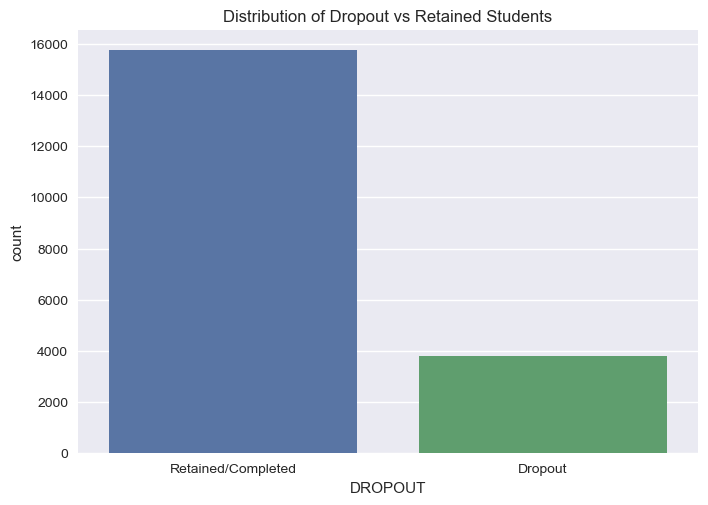

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="DROPOUT", data=student_features)
plt.title("Distribution of Dropout vs Retained Students")
plt.xticks([0, 1], ["Retained/Completed", "Dropout"])
plt.show()

In [53]:
# Remove students whose dropout status is unknown (NaN)
student_features_model = student_features.dropna(subset=["DROPOUT"]).copy()

print("Remaining rows after removing NaN dropout:")
print(student_features_model["DROPOUT"].value_counts())

Remaining rows after removing NaN dropout:
DROPOUT
0.0    15754
1.0     3802
Name: count, dtype: int64


In [54]:
# For numeric features
numeric_features = [
    'WAM_SCALED', 'PROGRESS_SCALED', 'FAIL_COUNT_SCALED', 'WITHDRAWAL_COUNT_SCALED', 'REPEAT_FAIL_COUNT_SCALED', 'AGE_SCALED'
]

correlations = student_features_model[numeric_features + ['DROPOUT']].corr()['DROPOUT'].sort_values(ascending=False)
print(correlations)

DROPOUT                     1.000000
FAIL_COUNT_SCALED           0.325006
REPEAT_FAIL_COUNT_SCALED    0.233772
WITHDRAWAL_COUNT_SCALED     0.161005
AGE_SCALED                  0.042778
WAM_SCALED                 -0.516164
PROGRESS_SCALED            -0.575726
Name: DROPOUT, dtype: float64


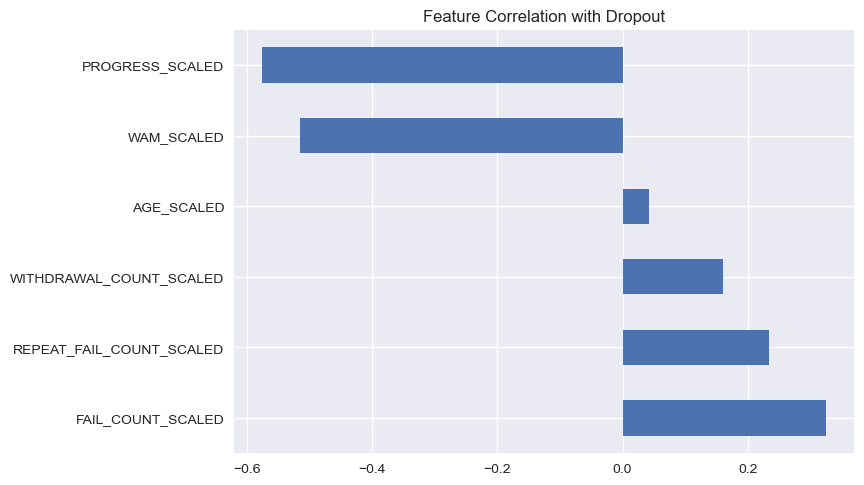

In [55]:
correlations.drop('DROPOUT').plot(kind='barh', title='Feature Correlation with Dropout')
plt.show()

Confusion Matrix:
 [[4513  213]
 [ 584  557]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.89      0.95      0.92      4726
         1.0       0.72      0.49      0.58      1141

    accuracy                           0.86      5867
   macro avg       0.80      0.72      0.75      5867
weighted avg       0.85      0.86      0.85      5867


AUC Score: 0.9027486264841815


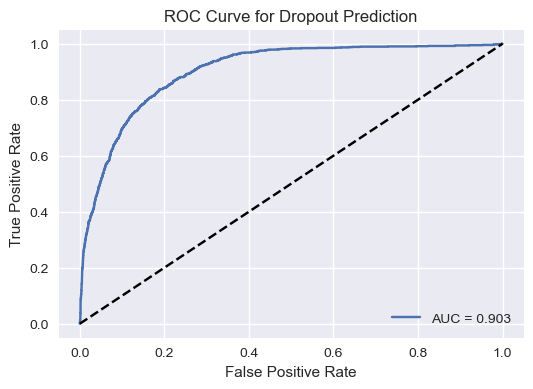

In [56]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

# Select top correlated features
selected_features = [
    'PROGRESS_SCALED',
    'WAM_SCALED',
    'FAIL_COUNT_SCALED',
    'REPEAT_FAIL_COUNT_SCALED',
    'WITHDRAWAL_COUNT_SCALED'
]

X = student_features_model[selected_features]
y = student_features_model['DROPOUT']

# Split data into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Train the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAUC Score:", roc_auc_score(y_test, y_prob))

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve for Dropout Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

The logistic regression model achieved an AUC of 0.90 and an accuracy of 86%.
Academic progress, weighted average marks (WAM), and failure counts were the strongest predictors of student dropout. Although the model identified 49% of true dropouts, it can be used as an early-warning system to flag students with declining academic performance for proactive intervention by academic advisors.

In [57]:
# List of categorical columns to test
categorical_features = ['GENDER', 'ENGLISH_BACKGROUND', 'STUDENT_TYPE']

# Run chi-square test for each
for col in categorical_features:
    if col in student_features_model.columns:
        contingency = pd.crosstab(student_features_model[col], student_features_model['DROPOUT'])
        chi2, p, dof, expected = chi2_contingency(contingency)
        print(f"{col}: chi2 = {chi2:.3f}, p = {p:.4f}")


GENDER: chi2 = 125.445, p = 0.0000
ENGLISH_BACKGROUND: chi2 = 74.355, p = 0.0000
STUDENT_TYPE: chi2 = 82.743, p = 0.0000


In [58]:
# Crosstab for easy interpretation
categorical_features = ['GENDER', 'ENGLISH_BACKGROUND', 'STUDENT_TYPE']

for col in categorical_features:
    if col in student_features_model.columns:
        ct = pd.crosstab(student_features_model[col], student_features_model['DROPOUT'], normalize='index') * 100
        print(f"\n{col} - Dropout Percentage by Category (%)")
        display(ct.round(2))


GENDER - Dropout Percentage by Category (%)


DROPOUT,0.0,1.0
GENDER,,
Female,84.3,15.7
Male,77.9,22.1
Non-binary,50.0,50.0



ENGLISH_BACKGROUND - Dropout Percentage by Category (%)


DROPOUT,0.0,1.0
ENGLISH_BACKGROUND,,
English Speaking Background,79.51,20.49
No Information,77.94,22.06
Non-English Speaking Background,84.71,15.29



STUDENT_TYPE - Dropout Percentage by Category (%)


DROPOUT,0.0,1.0
STUDENT_TYPE,,
Domestic,79.01,20.99
International,84.87,15.13


-Male students show a higher dropout risk overall, which may suggest different engagement or support patterns compared to female students.

-Non-English-speaking students appear to have lower dropout rates than English speakers. This could indicate stronger motivation or academic discipline among international students.

-Domestic students show higher dropout risk than international students. This aligns with engagement patterns found in other studies, where international students often remain more committed due to visa and financial obligations.

In [59]:
# Get each student's most recent academic year from combined_df
latest_year_per_student = (
    combined_df.groupby("UNIQUE_MQBS_STUDENT_IDENTIFIER")["ACADEMIC_YEAR"]
    .max()
    .reset_index()
    .rename(columns={"ACADEMIC_YEAR": "LATEST_ACADEMIC_YEAR"})
)

In [60]:
# Add latest academic year info to the student_features dataset
student_features = student_features.merge(
    latest_year_per_student,
    on="UNIQUE_MQBS_STUDENT_IDENTIFIER",
    how="left"
)

In [61]:
# Filter for students who are still active or retained (not completed) in 2025
latest_year = 2025  # or student_features['LATEST_ACADEMIC_YEAR'].max()

current_students_2025 = student_features[
    (student_features["LATEST_ACADEMIC_YEAR"] == latest_year) &
    (
        student_features["RESOLVED_RET_CODE_TAG"].isna() |
        (student_features["RESOLVED_RET_CODE_TAG"].str.strip() != "Completed")
    )
].copy()

print(f"Active / retained students in {latest_year}: {len(current_students_2025)}")

Active / retained students in 2025: 7079


In [62]:
# Predict dropout probability
X_new = current_students_2025[selected_features]
current_students_2025["PREDICTED_RISK"] = model.predict_proba(X_new)[:, 1]
current_students_2025["PREDICTED_AT_RISK"] = (current_students_2025["PREDICTED_RISK"] >= 0.8).astype(int)

In [63]:
bins   = [0.0, 0.20, 0.40, 0.60, 0.80, 1.00]
labels = ["0–20%","20–40%","40–60%","60–80%","80–100%"]
current_students_2025["RISK_BAND"] = pd.cut(current_students_2025["PREDICTED_RISK"], bins=bins, labels=labels, include_lowest=True)

In [64]:
cols_preview = [
    "UNIQUE_MQBS_STUDENT_IDENTIFIER","PREDICTED_RISK","PREDICTED_AT_RISK",
    "WAM","PROGRESS","FAIL_COUNT","WITHDRAWAL_COUNT","REPEAT_FAIL_COUNT"
]
cols_preview = [c for c in cols_preview if c in current_students_2025.columns]
display(current_students_2025.sort_values("PREDICTED_RISK", ascending=False)[cols_preview].head(10))

,UNIQUE_MQBS_STUDENT_IDENTIFIER,PREDICTED_RISK,PREDICTED_AT_RISK,WAM,PROGRESS,FAIL_COUNT,WITHDRAWAL_COUNT,REPEAT_FAIL_COUNT
10582,2510591,0.984612,1,6.50,3.125,20,0,14
9698,2509707,0.980543,1,15.18,0.000,19,0,14
9684,2509693,0.972550,1,11.47,6.250,19,4,11
19079,2519089,0.971849,1,10.75,0.000,12,0,8
16169,2516179,0.971329,1,5.11,0.000,9,3,5
20079,2520089,0.970389,1,3.00,0.000,8,0,4
18416,2518426,0.966478,1,5.73,0.000,11,0,4
12765,2512774,0.965856,1,5.00,0.000,8,4,3
13168,2513177,0.965333,1,0.00,0.000,0,8,0
18300,2518310,0.965025,1,0.00,0.000,0,7,0


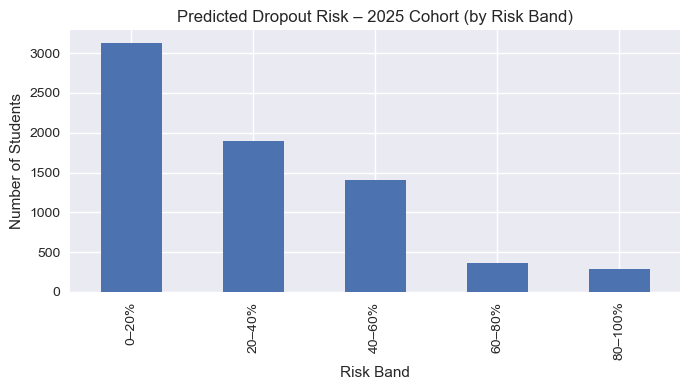

In [65]:
# Risk band distribution (bar)
band_counts = current_students_2025["RISK_BAND"].value_counts(dropna=False).sort_index()
plt.figure(figsize=(7,4))
band_counts.plot(kind="bar")
plt.title("Predicted Dropout Risk – 2025 Cohort (by Risk Band)")
plt.xlabel("Risk Band")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

-Most students are in the low-risk bands (0–20%), which is a good sign. The majority are stable.

-A smaller but important portion fall into 40–80%, which represents moderate-to-high risk.

-The 80–100% band, though smaller, represents the most critical students to intervene with urgently.

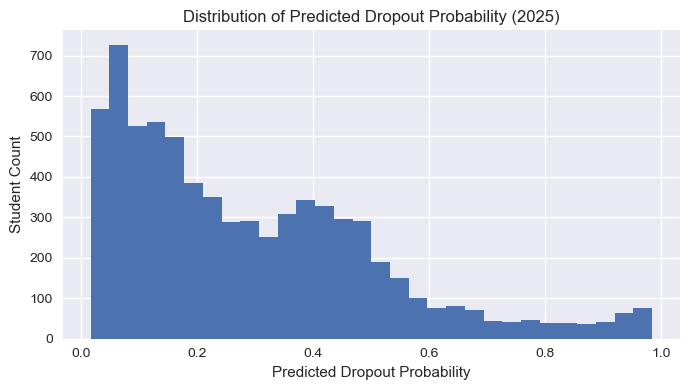

In [66]:
# Risk histogram
plt.figure(figsize=(7,4))
plt.hist(current_students_2025["PREDICTED_RISK"].dropna().values, bins=30)
plt.title("Distribution of Predicted Dropout Probability (2025)")
plt.xlabel("Predicted Dropout Probability")
plt.ylabel("Student Count")
plt.tight_layout()
plt.show()

-The left side (0–0.2) has the most students, showing most are low-risk.

-The right tail (0.8–1.0) represents a smaller number of high-risk students with a strong likelihood of dropping out.

-The gradual spread between 0.2–0.6 suggests there are many borderline or uncertain cases.

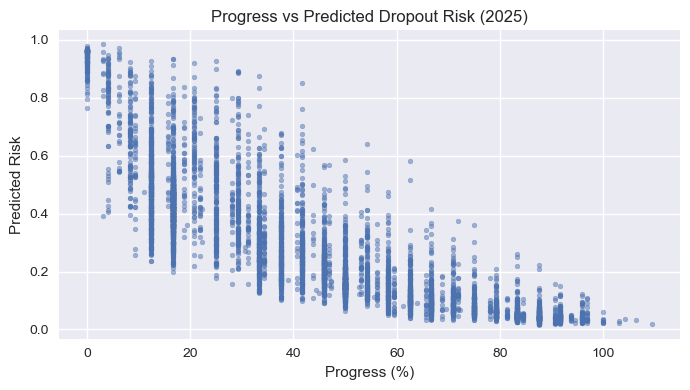

In [67]:
# Progress vs Risk scatter (early-warning map)
if "PROGRESS" in current_students_2025.columns:
    plt.figure(figsize=(7,4))
    plt.scatter(current_students_2025["PROGRESS"], current_students_2025["PREDICTED_RISK"], s=12, alpha=0.5)
    plt.title("Progress vs Predicted Dropout Risk (2025)")
    plt.xlabel("Progress (%)")
    plt.ylabel("Predicted Risk")
    plt.tight_layout()
    plt.show()

-There’s a clear negative relationship as students progress further through their course, their risk of dropping out decreases sharply.

-Students with low progress (<30%) have the highest risk (0.7–1.0).

-Those who are close to finishing (progress >80%) have very low risk (<0.2).

In [68]:
def mean_risk_by_quantile(df, col, q=5, title="", ax=None):  # ← added ax=None
    if col not in df.columns:
        print(f"{col} not in dataframe")
        return

    tmp = df[[col, "PREDICTED_RISK"]].dropna().copy()
    nunique = tmp[col].nunique(dropna=True)
    if nunique < 2:
        print(f"Not enough unique values in {col} to form quantiles (nunique={nunique}).")
        return

    quantiles = pd.qcut(tmp[col], q=min(q, nunique), duplicates="drop")
    n_bins = len(quantiles.cat.categories)
    labels = [f"Q{i+1}" for i in range(n_bins)]
    quantiles = quantiles.cat.rename_categories(labels)
    tmp[col + "_Q"] = quantiles

    gp = tmp.groupby(col + "_Q")["PREDICTED_RISK"].mean()

    # Plot on the provided axis if available
    if ax is not None:
        gp.plot(kind="bar", ax=ax)
        ax.set_title(title if title else f"Avg Predicted Risk by {col} Quantile")
        ax.set_xlabel(f"{col} (low → high)")
        ax.set_ylabel("Average Predicted Risk")
    else:
        plt.figure(figsize=(6, 4))
        gp.plot(kind="bar")
        plt.title(title if title else f"Avg Predicted Risk by {col} Quantile")
        plt.xlabel(f"{col} (low → high)")
        plt.ylabel("Average Predicted Risk")
        plt.tight_layout()
        plt.show()

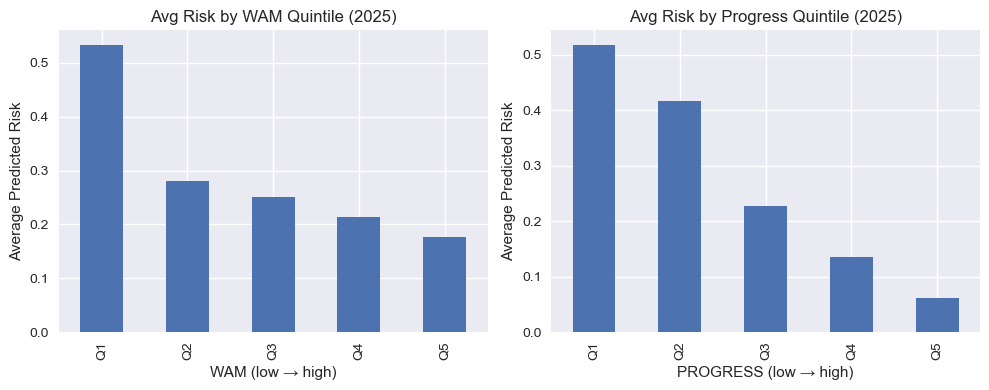

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

mean_risk_by_quantile(current_students_2025, "WAM", q=5,
                      title="Avg Risk by WAM Quintile (2025)", ax=axes[0])

mean_risk_by_quantile(current_students_2025, "PROGRESS", q=5,
                      title="Avg Risk by Progress Quintile (2025)", ax=axes[1])

plt.tight_layout()
plt.show()

-Low grades (WAM) + low progress = highest dropout probability.

-Interventions should prioritise students with Q1 in both charts with low WAM and slow progress as they combine academic difficulty + engagement issues.

In [70]:
# High-risk list
alert_cut = 0.80  # set your alert threshold
high = current_students_2025[current_students_2025["PREDICTED_RISK"] >= alert_cut]
print(f"High-risk students (>= {alert_cut:.0%}): {len(high)}")

high_cols = [c for c in ["UNIQUE_MQBS_STUDENT_IDENTIFIER","PREDICTED_RISK","WAM","PROGRESS","FAIL_COUNT","WITHDRAWAL_COUNT"] if c in current_students_2025.columns]
display(high[high_cols].sort_values("PREDICTED_RISK", ascending=False).head(30))

High-risk students (>= 80%): 285


,UNIQUE_MQBS_STUDENT_IDENTIFIER,PREDICTED_RISK,WAM,PROGRESS,FAIL_COUNT,WITHDRAWAL_COUNT
10582,2510591,0.984612,6.50,3.125,20,0
9698,2509707,0.980543,15.18,0.000,19,0
9684,2509693,0.972550,11.47,6.250,19,4
19079,2519089,0.971849,10.75,0.000,12,0
16169,2516179,0.971329,5.11,0.000,9,3
20079,2520089,0.970389,3.00,0.000,8,0
18416,2518426,0.966478,5.73,0.000,11,0
12765,2512774,0.965856,5.00,0.000,8,4
13168,2513177,0.965333,0.00,0.000,0,8
18300,2518310,0.965025,0.00,0.000,0,7


In [71]:
high_cols = [
    "UNIQUE_MQBS_STUDENT_IDENTIFIER",
    "PREDICTED_RISK",
    "WAM",
    "PROGRESS",
    "FAIL_COUNT",
    "WITHDRAWAL_COUNT",
    "LATEST_ACADEMIC_YEAR"
]

high[high_cols].to_csv("high_risk_students_2025.csv", index=False)

From a total of 7,079 students who remain active in 2025 (marked as “Not Retained in Year X + 1”), we set an alert threshold at 0.8 for predicted dropout probability.
The model identified 285 students (around 4%) whose predicted dropout risk exceeded 80%.
These students represent the highest-risk group who may need academic or engagement support. The university should prioritize follow-up communication, counseling, or intervention programs to help them stay on track for the next academic year.